# Notebook 5: Advanced Topics

## Topics Covered

1. **Articulation interpolation**: Morph between staccato and legato
2. **Parameter space clustering**: Articulations as regions in theta space
3. **Multi-voice articulations**: Trill, mordent, flam
4. **Lookahead and oversampling**: Performance features
5. **Design your own articulation**: Custom target → optimization

---

In [ ]:
import sys

sys.path.insert(0, "..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np

from hh_envelope.core import HEUConfig, HHEnvelopeUnit
from hh_envelope.polyphony.articulation import (
    ArticulatedNote,
    create_grace_note_config,
    create_mordent_config,
    create_trill_config,
)
from notebooks.utils.audio import display_audio, envelope_to_audio
from notebooks.utils.plotting import plot_gate_dynamics, setup_notebook_style
from notebooks.utils.signals import run_heu_simulation, run_heu_with_gates

setup_notebook_style()
print("Setup complete.")

Setup complete.


## 1. Articulation Interpolation

Can we smoothly morph between staccato and legato by interpolating theta values?

Since both articulations are just points in theta space, linear interpolation should produce intermediate articulations.

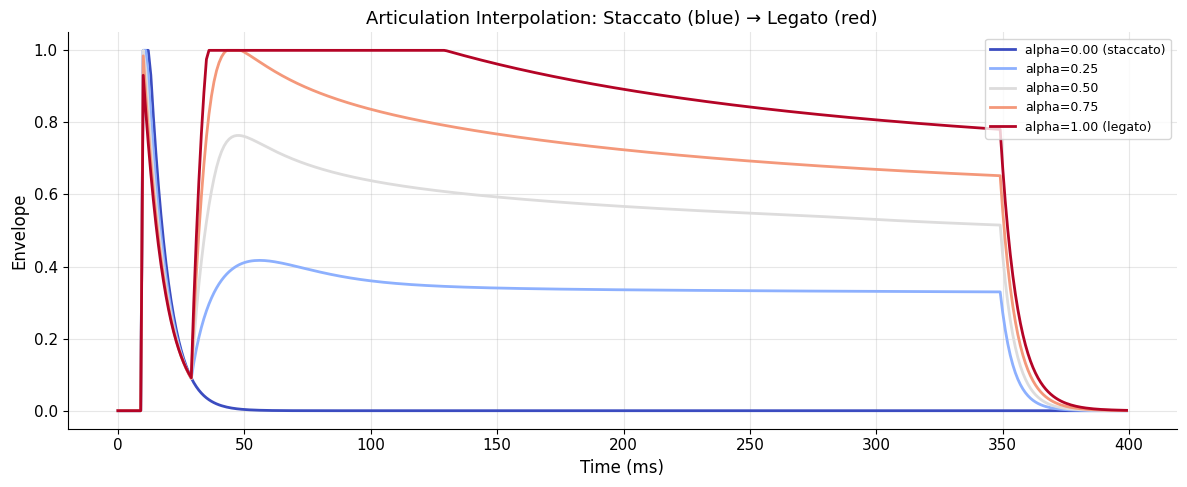

Smooth interpolation produces musically meaningful intermediate articulations.
This suggests the parameter space is well-structured for articulation control.


In [2]:
# Reference theta for staccato and legato
staccato_theta = {
    "theta_total": -1.0,
    "theta_balance": 1.5,
    "theta_attack_tau": -1.0,
    "theta_recovery_tau": 0.0,
}

legato_theta = {
    "theta_total": -2.0,
    "theta_balance": 2.0,
    "theta_attack_tau": 0.0,
    "theta_recovery_tau": -1.0,
}

# Interpolation weights
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
duration_ms = 400

# Input: pulse + partial tonic (intensity scales with alpha)
fig, ax = plt.subplots(figsize=(12, 5))
cmap = plt.cm.coolwarm

for alpha in alphas:
    # Interpolate theta
    interp_theta = {
        k: (1 - alpha) * staccato_theta[k] + alpha * legato_theta[k] for k in staccato_theta
    }

    # Create input (tonic intensity scales with alpha)
    signal = np.zeros(duration_ms)
    signal[10] = 1.5
    tonic_level = alpha * 0.35  # 0 for staccato, 0.35 for legato
    signal[30:350] = tonic_level

    # Run
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(interp_theta)
    envelope, _ = run_heu_simulation(unit, signal)

    color = cmap(alpha)
    label = f"alpha={alpha:.2f}" + (
        " (staccato)" if alpha == 0 else " (legato)" if alpha == 1 else ""
    )
    ax.plot(envelope, color=color, linewidth=2, label=label)

ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Articulation Interpolation: Staccato (blue) → Legato (red)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Smooth interpolation produces musically meaningful intermediate articulations.")
print("This suggests the parameter space is well-structured for articulation control.")

## 2. Parameter Space Exploration

Let's map the articulation space by sweeping two key parameters and measuring the resulting envelope characteristics.

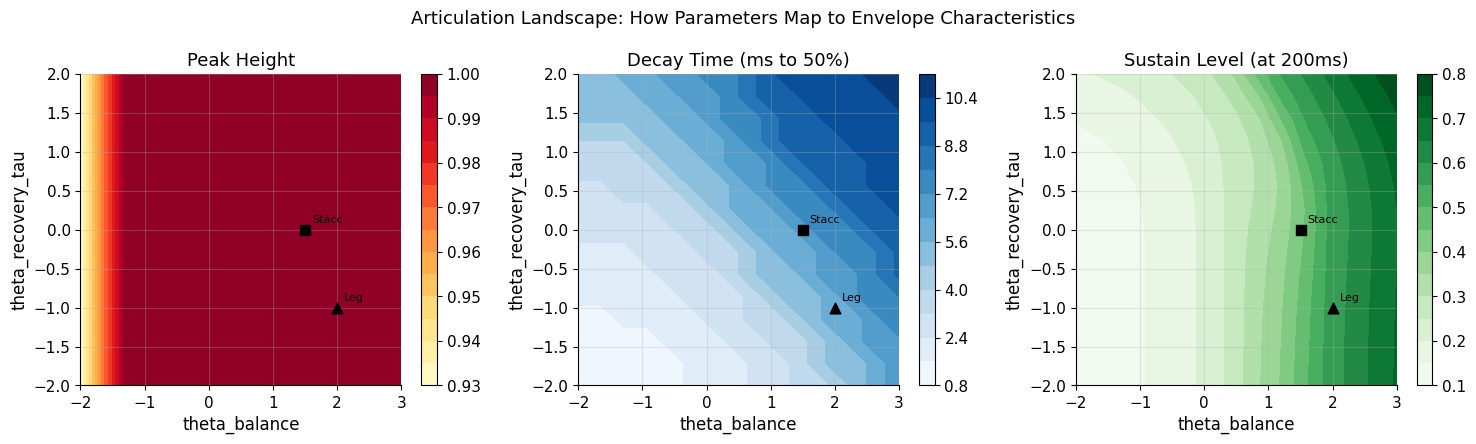

Black markers show reference staccato (square) and legato (triangle).
The parameter space is smooth and well-structured.


In [3]:
# Sweep theta_balance and theta_recovery_tau
# Measure: peak height, decay time, sustain level

balance_range = np.linspace(-2, 3, 15)
recovery_range = np.linspace(-2, 2, 15)

# Input with tonic (to reveal sustain behavior)
duration_ms = 300
test_signal = np.zeros(duration_ms)
test_signal[10] = 1.5
test_signal[30:250] = 0.2

peak_grid = np.zeros((len(recovery_range), len(balance_range)))
sustain_grid = np.zeros_like(peak_grid)
decay_grid = np.zeros_like(peak_grid)

for i, recovery in enumerate(recovery_range):
    for j, balance in enumerate(balance_range):
        unit = HHEnvelopeUnit()
        unit.set_theta(theta_balance=balance, theta_recovery_tau=recovery)
        env, _ = run_heu_simulation(unit, test_signal)

        peak_grid[i, j] = env.max()
        sustain_grid[i, j] = env[200] if len(env) > 200 else 0  # Level at 200ms

        # Decay time: time from peak to 50% of peak
        peak_idx = np.argmax(env)
        half_peak = env.max() * 0.5
        decay_indices = np.where(env[peak_idx:] < half_peak)[0]
        decay_grid[i, j] = decay_indices[0] if len(decay_indices) > 0 else duration_ms

# Plot three characteristics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, data, title, cmap_name in zip(
    axes,
    [peak_grid, decay_grid, sustain_grid],
    ["Peak Height", "Decay Time (ms to 50%)", "Sustain Level (at 200ms)"],
    ["YlOrRd", "Blues", "Greens"],
):
    im = ax.contourf(balance_range, recovery_range, data, levels=15, cmap=cmap_name)
    plt.colorbar(im, ax=ax)
    ax.set_xlabel("theta_balance")
    ax.set_ylabel("theta_recovery_tau")
    ax.set_title(title)

    # Mark known articulations
    ax.scatter(1.5, 0.0, color="black", s=60, marker="s", zorder=5)
    ax.scatter(2.0, -1.0, color="black", s=60, marker="^", zorder=5)
    ax.annotate("Stacc", (1.5, 0.0), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.annotate("Leg", (2.0, -1.0), textcoords="offset points", xytext=(5, 5), fontsize=8)

fig.suptitle("Articulation Landscape: How Parameters Map to Envelope Characteristics", fontsize=13)
plt.tight_layout()
plt.show()

print("Black markers show reference staccato (square) and legato (triangle).")
print("The parameter space is smooth and well-structured.")

## 3. Multi-Voice Articulations

The `ArticulatedNote` class supports various multi-voice patterns beyond grace notes.

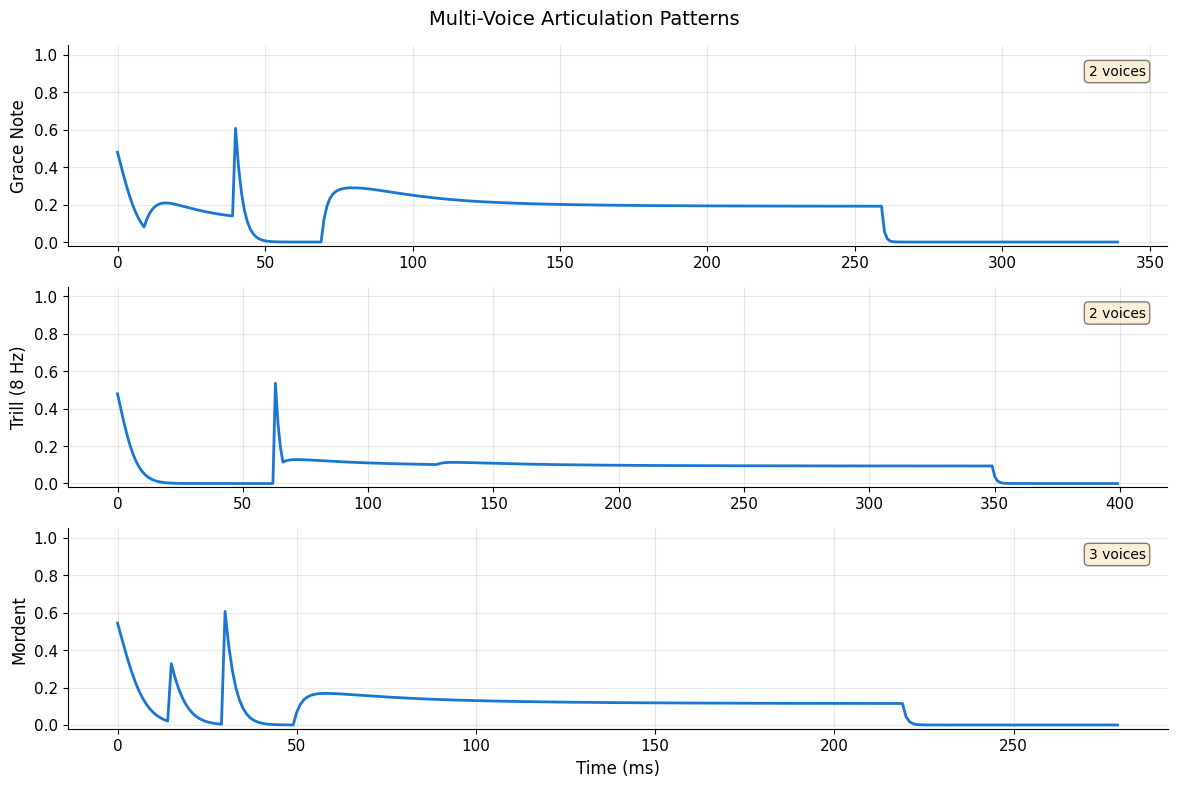

Each pattern uses multiple independent HEUs combined via max().
Voices have independent theta, tonic, and lifetime configurations.


In [4]:
# Create three articulation types
grace_config = create_grace_note_config(main_duration_ms=300.0)
trill_config = create_trill_config(duration_ms=400.0, rate_hz=8.0)
mordent_config = create_mordent_config(main_duration_ms=250.0)

configs = [
    ("Grace Note", grace_config),
    ("Trill (8 Hz)", trill_config),
    ("Mordent", mordent_config),
]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=False)

for idx, (name, config) in enumerate(configs):
    note = ArticulatedNote(config)
    envelope = note.run_full(dt_ms=1.0)

    time = np.arange(len(envelope))
    axes[idx].plot(time, envelope, color="#1976D2", linewidth=2)
    axes[idx].set_ylabel(name)
    axes[idx].set_ylim([-0.02, 1.05])

    # Annotate voice count
    n_voices = len(config.voice_roles)
    axes[idx].text(
        0.98,
        0.85,
        f"{n_voices} voices",
        transform=axes[idx].transAxes,
        ha="right",
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    )

axes[-1].set_xlabel("Time (ms)")
fig.suptitle("Multi-Voice Articulation Patterns", fontsize=14)
plt.tight_layout()
plt.show()

print("Each pattern uses multiple independent HEUs combined via max().")
print("Voices have independent theta, tonic, and lifetime configurations.")

## 4. Lookahead and Oversampling

V1.0 added two performance features:
- **Lookahead**: Compressor-style anticipation prevents peak clipping
- **Oversampling**: Higher internal rate improves transient accuracy

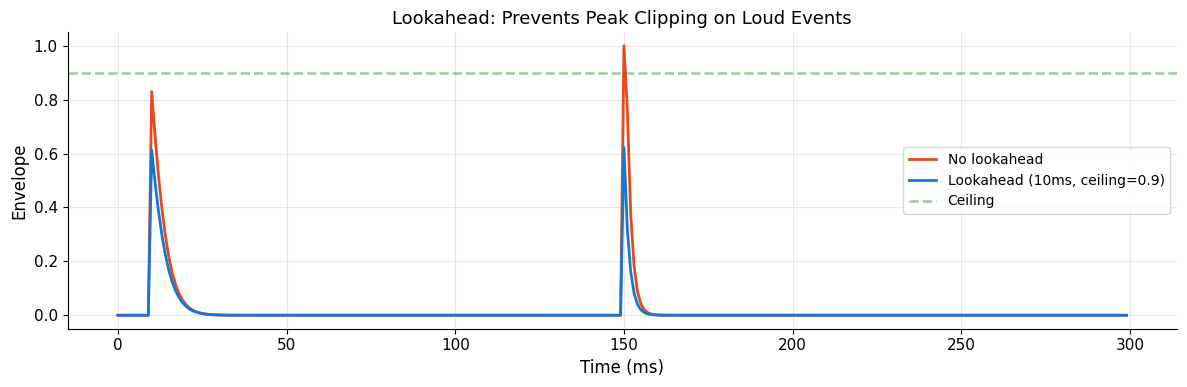

Without lookahead - peak: 1.000
With lookahead - peak: 0.623

Lookahead anticipates the loud pulse and reduces gain preemptively.


In [5]:
# Compare with and without lookahead
duration_ms = 300
signal = np.zeros(duration_ms)
# Two pulses: normal then loud
signal[10] = 1.0
signal[150] = 3.0  # Very loud - might clip

# No lookahead
unit_basic = HHEnvelopeUnit()
env_basic, _ = run_heu_simulation(unit_basic, signal)

# With lookahead
config_la = HEUConfig(lookahead_ms=10.0, lookahead_mode="peak", lookahead_ceiling=0.9)
unit_la = HHEnvelopeUnit(config=config_la)
# Must use batch processing for lookahead
outputs_la = unit_la.process_batch(signal.tolist(), dt_ms=1.0)
env_la = np.array([o.envelope for o in outputs_la])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(env_basic, color="#E64A19", linewidth=2, label="No lookahead")
ax.plot(env_la, color="#1976D2", linewidth=2, label="Lookahead (10ms, ceiling=0.9)")
ax.axhline(0.9, color="green", linestyle="--", alpha=0.4, label="Ceiling")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Lookahead: Prevents Peak Clipping on Loud Events")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Without lookahead - peak: {env_basic.max():.3f}")
print(f"With lookahead - peak: {env_la.max():.3f}")
print("\nLookahead anticipates the loud pulse and reduces gain preemptively.")

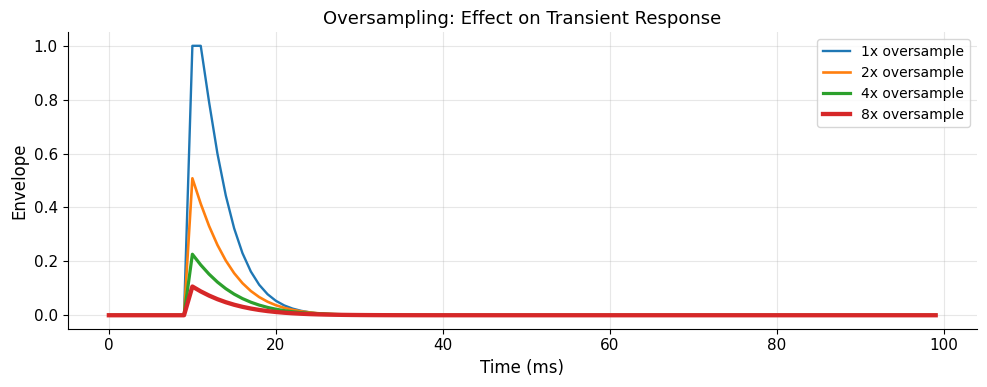

Higher oversampling gives smoother transient curves.
The difference is subtle at 1kHz control rate.


In [6]:
# Compare oversampling rates
signal = np.zeros(100)
signal[10] = 1.5

oversample_factors = [1, 2, 4, 8]

fig, ax = plt.subplots(figsize=(10, 4))

for factor in oversample_factors:
    config = HEUConfig(oversample_factor=factor)
    unit = HHEnvelopeUnit(config=config)
    env, _ = run_heu_simulation(unit, signal)
    ax.plot(env, linewidth=1.5 + factor * 0.2, label=f"{factor}x oversample")

ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Oversampling: Effect on Transient Response")
ax.legend()
plt.tight_layout()
plt.show()

print("Higher oversampling gives smoother transient curves.")
print("The difference is subtle at 1kHz control rate.")

## 5. Design Your Own Articulation

Use the tools from this notebook series to design custom articulations.

### Workflow:
1. Choose parameters by musical intent
2. Generate the envelope
3. Listen to it
4. Adjust and iterate

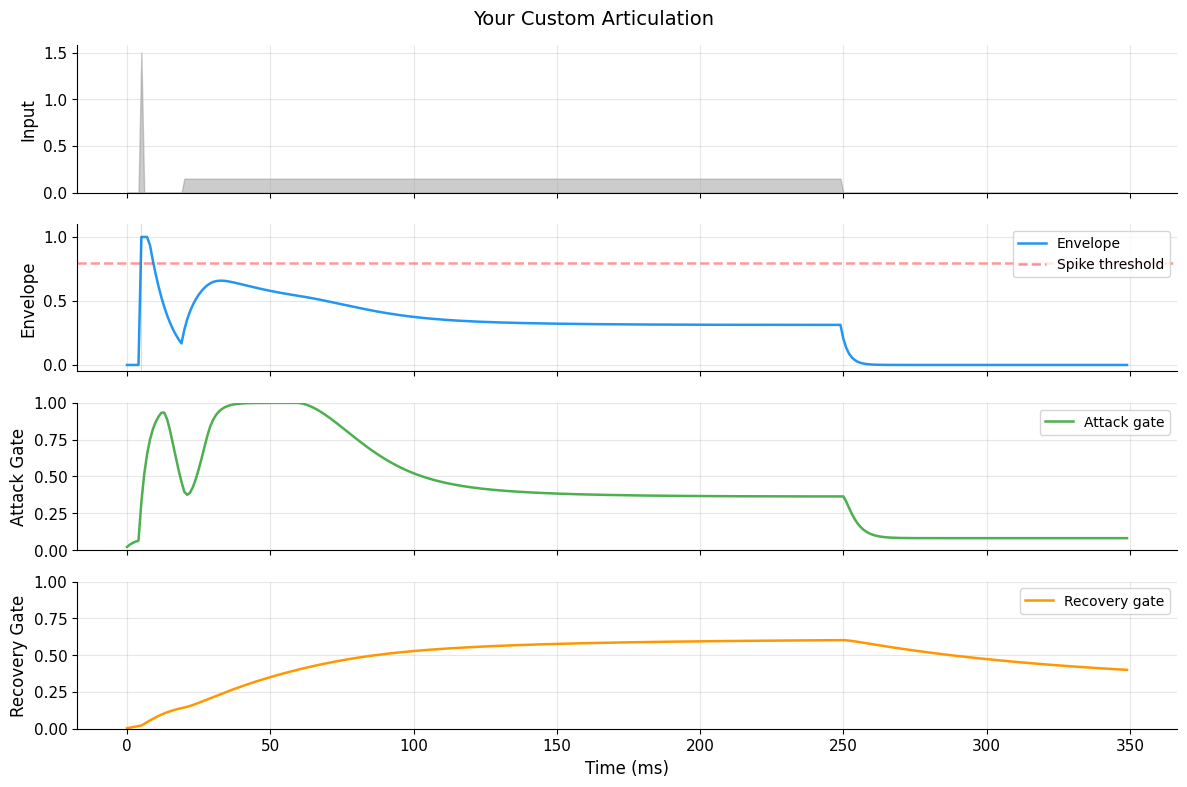


Listen to your articulation:



Envelope statistics:
  Peak: 1.000
  Time to peak: 5 ms
  Sustain level (at 200ms): 0.314
  Spikes: 1


In [ ]:
# Interactive articulation designer
# Modify these parameters to create your own articulation

# === ADJUST THESE ===
my_theta = {
    "theta_total": -0.5,  # Higher = more responsive
    "theta_balance": 1.0,  # Positive = attack-biased, Negative = recovery-biased
    "theta_attack_tau": -0.5,  # Negative = faster attack
    "theta_recovery_tau": 0.5,  # Positive = slower decay
}

my_pulse_amplitude = 1.5  # Initial impulse strength
my_tonic_level = 0.15  # Sustained input (0 = staccato, 0.3+ = legato)
my_tonic_start_ms = 20  # When tonic begins
my_tonic_end_ms = 250  # When tonic ends
my_duration_ms = 350  # Total duration
# === END ADJUST ===

# Generate signal
signal = np.zeros(my_duration_ms)
signal[5] = my_pulse_amplitude
if my_tonic_level > 0:
    signal[my_tonic_start_ms:my_tonic_end_ms] = my_tonic_level

# Run HEU
unit = HHEnvelopeUnit()
unit.set_theta_from_dict(my_theta)
result = run_heu_with_gates(unit, signal)

# Plot
fig = plot_gate_dynamics(
    voltage=result.envelope,
    attack_gate=result.attack_gate,
    recovery_gate=result.recovery_gate,
    time_ms=result.time_ms,
    input_signal=result.input_signal,
    spike_times=result.spike_times,
    title="Your Custom Articulation",
)
plt.show()

# Audio
audio, sr = envelope_to_audio(result.envelope, carrier_freq=440.0)
print("\nListen to your articulation:")
display_audio(audio, sr)

print("\nEnvelope statistics:")
print(f"  Peak: {result.envelope.max():.3f}")
print(f"  Time to peak: {np.argmax(result.envelope)} ms")
print(f"  Sustain level (at 200ms): {result.envelope[min(200, len(result.envelope) - 1)]:.3f}")
print(f"  Spikes: {len(result.spike_times)}")

## 6. Phrase-Level Modulation (Conceptual)

In the full hierarchy, slower layers modulate faster layers' parameters over time. Here's a preview of how that works.

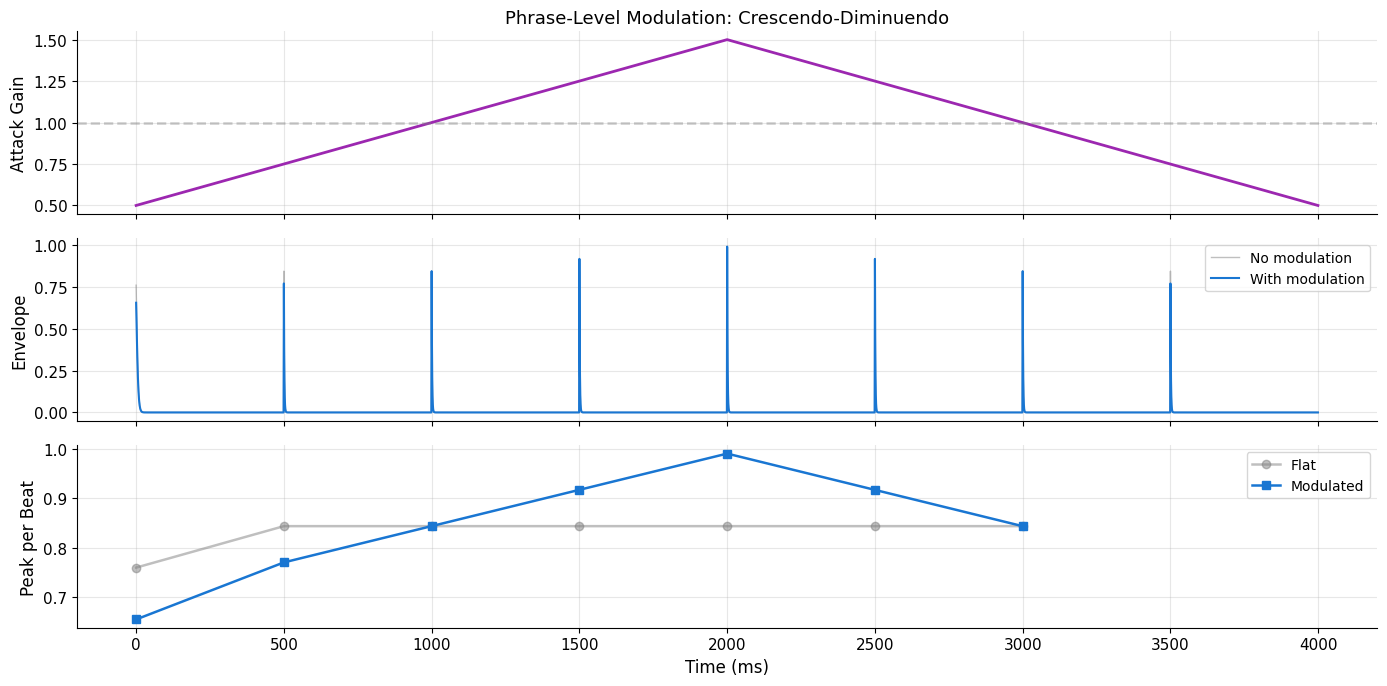

Phrase-level modulation creates musical crescendo/diminuendo
by varying attack_gain over the phrase arc.

This is the hierarchy principle in action:
  Slow layer (phrase) modulates PARAMETERS of fast layer (note).


In [8]:
# Simulate phrase-level modulation:
# A slow "tension" signal modulates attack_gain over a phrase

from hh_envelope.core import HEUModulators
from hh_envelope.utils.signals import pulse_train

bpm = 120
duration_sec = 4.0
time_ms, signal = pulse_train(bpm, duration_sec)

# Phrase tension: crescendo then diminuendo
n_samples = len(signal)
phrase_tension = np.zeros(n_samples)
midpoint = n_samples // 2

# Crescendo: 0.5 → 1.5 attack_gain
phrase_tension[:midpoint] = np.linspace(0.5, 1.5, midpoint)
# Diminuendo: 1.5 → 0.5
phrase_tension[midpoint:] = np.linspace(1.5, 0.5, n_samples - midpoint)

# Run with modulation
unit = HHEnvelopeUnit()
env_modulated = []
for i, exc in enumerate(signal):
    mod = HEUModulators(attack_gain=phrase_tension[i])
    out = unit.step(exc, dt_ms=1.0, mod=mod)
    env_modulated.append(out.envelope)

env_modulated = np.array(env_modulated)

# Also run without modulation for comparison
unit2 = HHEnvelopeUnit()
env_flat = []
for exc in signal:
    out = unit2.step(exc, dt_ms=1.0)
    env_flat.append(out.envelope)
env_flat = np.array(env_flat)

# Plot
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time_ms, phrase_tension, color="#9C27B0", linewidth=2)
axes[0].set_ylabel("Attack Gain")
axes[0].set_title("Phrase-Level Modulation: Crescendo-Diminuendo")
axes[0].axhline(1.0, color="gray", linestyle="--", alpha=0.4)

axes[1].plot(time_ms, env_flat, color="gray", alpha=0.5, linewidth=1, label="No modulation")
axes[1].plot(time_ms, env_modulated, color="#1976D2", linewidth=1.5, label="With modulation")
axes[1].set_ylabel("Envelope")
axes[1].legend()

# Show peak per beat
beat_period = int(60000 / bpm)
peaks_mod = []
peaks_flat = []
for beat_start in range(0, n_samples - beat_period, beat_period):
    peaks_mod.append(env_modulated[beat_start : beat_start + beat_period].max())
    peaks_flat.append(env_flat[beat_start : beat_start + beat_period].max())

beat_times = np.arange(len(peaks_mod)) * beat_period
axes[2].plot(beat_times, peaks_flat, "o-", color="gray", alpha=0.5, label="Flat")
axes[2].plot(beat_times, peaks_mod, "s-", color="#1976D2", label="Modulated")
axes[2].set_ylabel("Peak per Beat")
axes[2].set_xlabel("Time (ms)")
axes[2].legend()

plt.tight_layout()
plt.show()

print("Phrase-level modulation creates musical crescendo/diminuendo")
print("by varying attack_gain over the phrase arc.")
print("\nThis is the hierarchy principle in action:")
print("  Slow layer (phrase) modulates PARAMETERS of fast layer (note).")

## 7. Summary: What We've Learned

Across these notebooks, we've demonstrated:

1. **Core dynamics** (Notebook 0): The HEU is an excitable dynamical system with self-amplifying attack, delayed recovery, and refractory period.

2. **Tempo locking** (Notebook 1): The HEU phase-locks to rhythmic input with PLV=1.0, shows natural accent compression (1.19x), and is robust to timing jitter.

3. **Voice coupling** (Notebook 2): Parameter-modulating coupling preserves input integrity while creating consonance-biased dynamics. No voice suppression.

4. **Envelope fitting** (Notebook 3): CMA-ES recovers reference parameters with MSE < 0.001. Multiple solutions exist (smooth landscape).

5. **Architectural limits** (Notebook 4): Single-voice HEU fundamentally cannot match certain multi-peak articulations. Two-voice architecture provides 2-2888x improvement in the conflict region.

### The Architecture in One Sentence

> **Multiple excitable dynamical units with independent parameters, combined via max(), can produce articulated musical gestures that no single unit can achieve.**

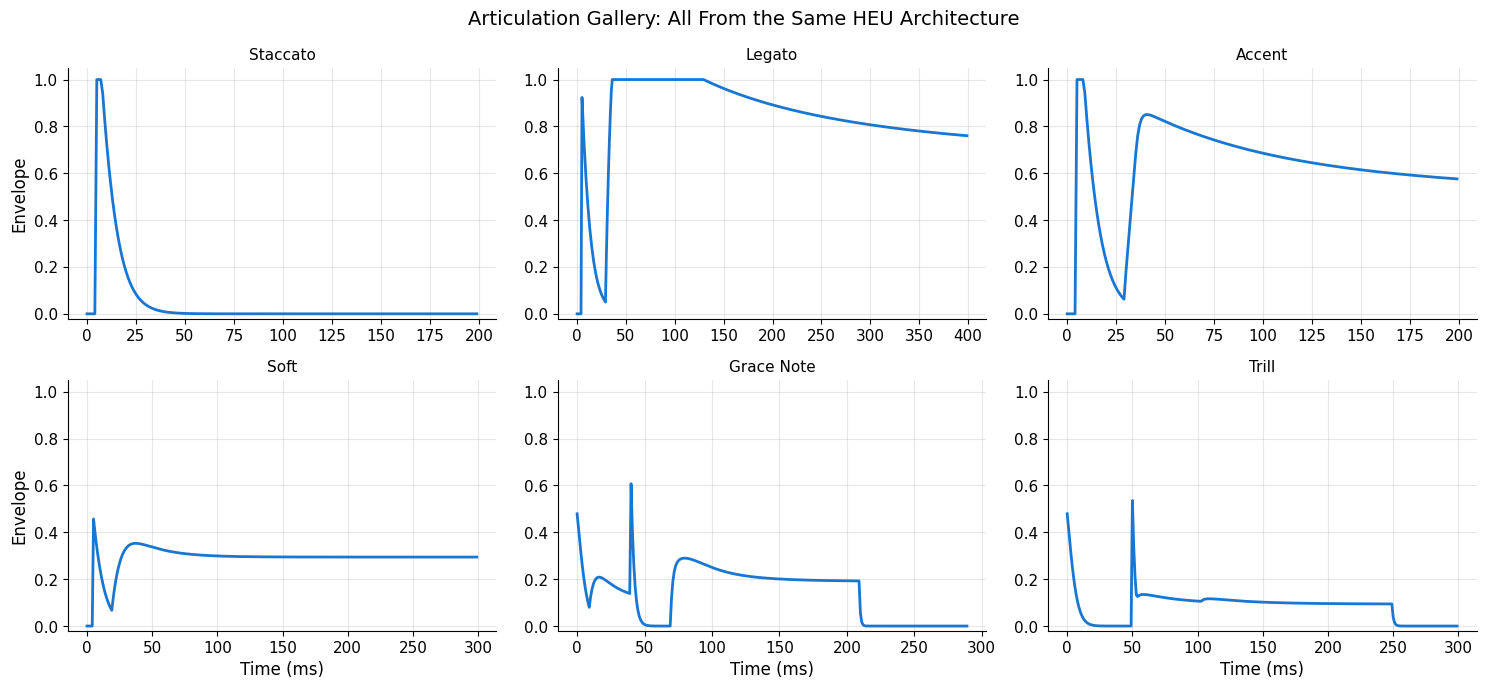

All articulations emerge from the same excitable dynamics.
Only the parameters (theta) and input pattern differ.


In [9]:
# Final demonstration: all articulations in one view
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

articulations = [
    (
        "Staccato",
        {
            "theta_total": -1.0,
            "theta_balance": 1.5,
            "theta_attack_tau": -1.0,
            "theta_recovery_tau": 0.0,
        },
        lambda: (np.zeros(200), 1.5, 0, 0),
    ),  # signal, pulse, tonic_start, tonic_level
    (
        "Legato",
        {
            "theta_total": -2.0,
            "theta_balance": 2.0,
            "theta_attack_tau": 0.0,
            "theta_recovery_tau": -1.0,
        },
        lambda: (np.zeros(400), 1.5, 30, 0.35),
    ),
    (
        "Accent",
        {
            "theta_total": 0.0,
            "theta_balance": 2.5,
            "theta_attack_tau": -1.5,
            "theta_recovery_tau": 0.5,
        },
        lambda: (np.zeros(200), 2.0, 30, 0.15),
    ),
    (
        "Soft",
        {
            "theta_total": -2.0,
            "theta_balance": 0.0,
            "theta_attack_tau": 0.5,
            "theta_recovery_tau": -0.5,
        },
        lambda: (np.zeros(300), 0.8, 20, 0.1),
    ),
    ("Grace Note", None, None),  # Special: uses ArticulatedNote
    ("Trill", None, None),  # Special: uses ArticulatedNote
]

for idx, (name, theta, sig_fn) in enumerate(articulations):
    row, col = idx // 3, idx % 3

    if name == "Grace Note":
        note = ArticulatedNote(create_grace_note_config(main_duration_ms=250.0))
        env = note.run_full(dt_ms=1.0)
    elif name == "Trill":
        note = ArticulatedNote(create_trill_config(duration_ms=300.0, rate_hz=10.0))
        env = note.run_full(dt_ms=1.0)
    else:
        signal_base, pulse_amp, tonic_start, tonic_level = sig_fn()
        signal_base[5] = pulse_amp
        if tonic_level > 0:
            signal_base[tonic_start:] = tonic_level
        unit = HHEnvelopeUnit()
        unit.set_theta_from_dict(theta)
        env, _ = run_heu_simulation(unit, signal_base)

    axes[row, col].plot(env, color="#1976D2", linewidth=2)
    axes[row, col].set_title(name, fontsize=11)
    axes[row, col].set_ylim([-0.02, 1.05])
    if col == 0:
        axes[row, col].set_ylabel("Envelope")
    if row == 1:
        axes[row, col].set_xlabel("Time (ms)")

fig.suptitle("Articulation Gallery: All From the Same HEU Architecture", fontsize=14)
plt.tight_layout()
plt.show()

print("All articulations emerge from the same excitable dynamics.")
print("Only the parameters (theta) and input pattern differ.")